In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#visual style charts

sns.set_style("whitegrid")
# Set random seed so your numbers match this lesson exactly

np.random.seed(42)

n_events = 200

# Synthetic real-world log records spanning the last 14 days

data = {
    'event_id': [f"EVT_{2000+i}" for i in range(n_events)],
    'student_id': np.random.choice([f"STU_{10+i}" for i in range(12)], size=n_events),
    'course_name': np.random.choice(['Intro to Python', 'Calculus I', 'Statistics'], size=n_events),
    'action': np.random.choice(
        ['login', 'view_lecture', 'submit_assignment', 'post_forum', 'download_resource'], 
        size=n_events, 
        p=[0.30, 0.35, 0.15, 0.10, 0.10] # Probability: views & logins are most common
    ),
    # Timestamps spread across September 2026
    'timestamp': pd.date_range(start='2026-09-01 08:00:00', end='2026-09-14 23:59:00', periods=n_events)
}

df_logs = pd.DataFrame(data)

print("✅ LMS EVENT LOGS INITIALIZED SUCCESSFULLY!")
print(f"Total recorded click events: {len(df_logs)}")
print("\nFirst 5 raw server log rows:")
df_logs.head()

✅ LMS EVENT LOGS INITIALIZED SUCCESSFULLY!
Total recorded click events: 200

First 5 raw server log rows:


,event_id,student_id,course_name,action,timestamp
0,EVT_2000,STU_16,Statistics,submit_assignment,2026-09-01 08:00:00.000000
1,EVT_2001,STU_13,Statistics,post_forum,2026-09-01 09:38:53.366834
2,EVT_2002,STU_20,Calculus I,view_lecture,2026-09-01 11:17:46.733668
3,EVT_2003,STU_17,Intro to Python,view_lecture,2026-09-01 12:56:40.100502
4,EVT_2004,STU_14,Intro to Python,login,2026-09-01 14:35:33.467336


In [2]:
# ==========================================================
# STEP 2: DATETIME FEATURE EXTRACTION
# ==========================================================
# 1. Ensure the timestamp column is a true datetime object
df_logs['timestamp'] = pd.to_datetime(df_logs['timestamp'])

# 2. Extract useful time-based columns:
# .dt.hour -> Extracts the hour of the day (0 to 23)
df_logs['hour_of_day'] = df_logs['timestamp'].dt.hour

# .dt.day_name() -> Extracts 'Monday', 'Tuesday', etc.
df_logs['day_of_week'] = df_logs['timestamp'].dt.day_name()

# .dt.date -> Extracts just the date without the time (e.g., '2026-09-01')
df_logs['log_date'] = df_logs['timestamp'].dt.date
print("--- LOGS WITH TIME FEATURES EXTRACTED ---")
df_logs[['student_id', 'action', 'timestamp', 'day_of_week', 'hour_of_day']].head()

--- LOGS WITH TIME FEATURES EXTRACTED ---


,student_id,action,timestamp,day_of_week,hour_of_day
0,STU_16,submit_assignment,2026-09-01 08:00:00.000000,Tuesday,8
1,STU_13,post_forum,2026-09-01 09:38:53.366834,Tuesday,9
2,STU_20,view_lecture,2026-09-01 11:17:46.733668,Tuesday,11
3,STU_17,view_lecture,2026-09-01 12:56:40.100502,Tuesday,12
4,STU_14,login,2026-09-01 14:35:33.467336,Tuesday,14


In [4]:
# ==========================================================
# STEP 3: INACTIVITY & RETENTION RISK ENGINE
# ==========================================================

# Current evaluation date (the "today" of our dataset)
current_system_date = pd.to_datetime('2026-09-14 23:59:59')
# 1. Group by student and find the MAXIMUM (most recent) timestamp for each
last_active = df_logs.groupby('student_id').agg(
    total_actions=('action', 'count'), 
    last_seen=('timestamp', 'max')
).reset_index()

# 2. Calculate days since last active
# (current_system_date - last_seen).dt.days computes the integer difference in days
last_active['days_inactive'] = (current_system_date - last_active['last_seen']).dt.days

# 3. Apply business logic: Flag students missing for 5+ days
def flag_engagement(days):
    if days >= 5:
        return 'High Risk (Inactive 5+ days)'
    elif days >= 3:
        return 'Moderate (Inactive 3+ days)'
    else:
        return 'Active (Last 48 hours)'

last_active['engagement_status'] = last_active['days_inactive'].apply(flag_engagement)

# Sort by most inactive students at the top
last_active = last_active.sort_values('days_inactive', ascending=False).reset_index(drop=True)

print("--- STUDENT ENGAGEMENT AUDIT TABLE ---")
print(last_active)

--- STUDENT ENGAGEMENT AUDIT TABLE ---
   student_id  total_actions                  last_seen  days_inactive  \
0      STU_11             12 2026-09-12 19:14:32.261306              2   
1      STU_21             27 2026-09-13 16:40:06.030150              1   
2      STU_10             14 2026-09-14 20:41:13.266331              0   
3      STU_12             17 2026-09-14 22:20:06.633165              0   
4      STU_13             14 2026-09-14 05:51:12.964824              0   
5      STU_14             16 2026-09-14 19:02:19.899497              0   
6      STU_15             10 2026-09-14 12:26:46.432160              0   
7      STU_16             22 2026-09-14 10:47:53.065326              0   
8      STU_17             18 2026-09-14 14:05:39.798994              0   
9      STU_18             19 2026-09-14 17:23:26.532663              0   
10     STU_19             17 2026-09-14 23:59:00.000000              0   
11     STU_20             14 2026-09-14 15:44:33.165829              0   

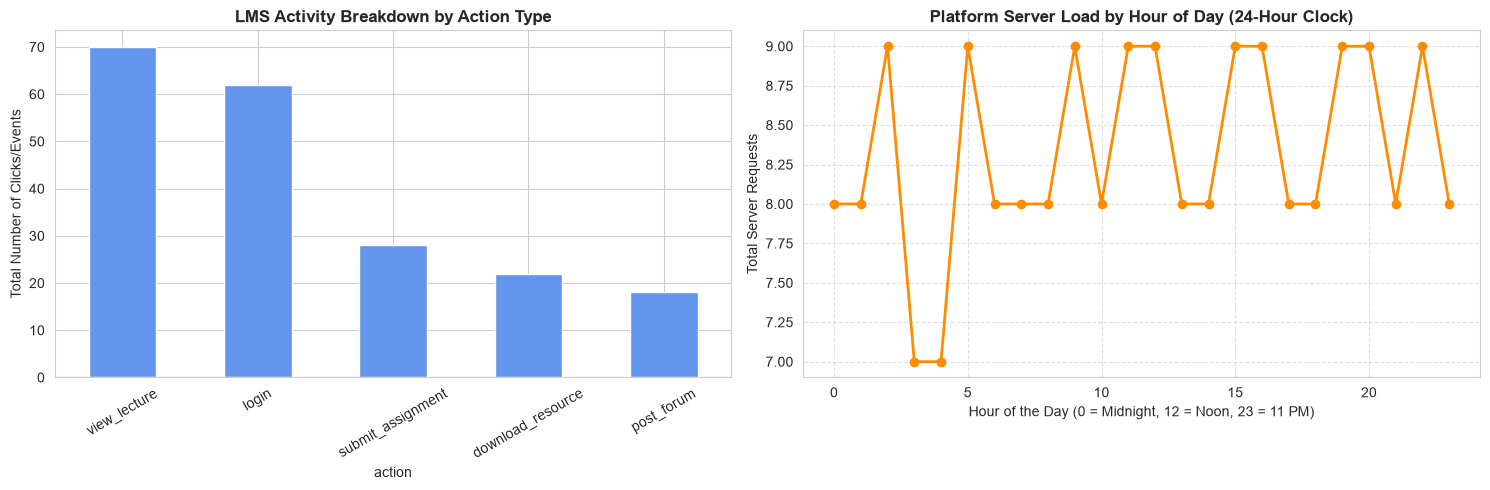

In [5]:
# ==========================================================
# STEP 4: PLATFORM USAGE & TRAFFIC DASHBOARD
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- CHART 1: What types of actions are happening on the LMS? ---
action_counts = df_logs['action'].value_counts()
action_counts.plot(kind='bar', ax=axes[0], color='cornflowerblue')
axes[0].set_title('LMS Activity Breakdown by Action Type', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Number of Clicks/Events')
axes[0].tick_params(axis='x', rotation=30)

# --- CHART 2: Peak Traffic by Hour of Day ---
# Shows at what times students are online
hourly_traffic = df_logs.groupby('hour_of_day').size()
hourly_traffic.plot(kind='line', marker='o', ax=axes[1], color='darkorange', linewidth=2)
axes[1].set_title('Platform Server Load by Hour of Day (24-Hour Clock)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour of the Day (0 = Midnight, 12 = Noon, 23 = 11 PM)')
axes[1].set_ylabel('Total Server Requests')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [6]:
# ==========================================================
# STEP 5: EXPORT INACTIVE STUDENTS ALERT
# ==========================================================

# Filter only students who are High Risk
inactive_students_report = last_active[last_active['days_inactive'] >= 5]

# Export to CSV with an automated date stamp
export_filename = f"LMS_Inactive_Students_Alert_{current_system_date.strftime('%Y-%m-%d')}.csv"
inactive_students_report.to_csv(export_filename, index=False)

print(f"🚨 ALERT REPORT GENERATED: {export_filename}")
print(f"Total students flagged for intervention: {len(inactive_students_report)}")
print(inactive_students_report[['student_id', 'days_inactive', 'engagement_status']])

🚨 ALERT REPORT GENERATED: LMS_Inactive_Students_Alert_2026-09-14.csv
Total students flagged for intervention: 0
Empty DataFrame
Columns: [student_id, days_inactive, engagement_status]
Index: []


In [7]:
submissions = df_logs[df_logs['action'] == 'submit_assignment']
submissions_by_course = submissions['course_name'].value_counts()
print(submissions_by_course)

course_name
Statistics         11
Intro to Python     9
Calculus I          8
Name: count, dtype: int64
